In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Determine relative path to sample data
data_path = '../../data/raw_sample_data.csv' if os.path.exists('../../data/raw_sample_data.csv') else 'data/raw_sample_data.csv'

# Check if data file exists; if not, create mock dataset automatically
if not os.path.exists(data_path):
    os.makedirs(os.path.dirname(data_path), exist_ok=True)
    np.random.seed(42)
    dates = pd.date_range('2026-10-01', periods=100, freq='h')
    cities = ['delhi', 'mumbai', 'bengaluru', 'chennai', 'kolkata', 'hyderabad', 'ahmedabad', 'pune']
    params = ['pm25', 'pm10', 'no2', 'so2']
    
    data = []
    for city in cities:
        for dt in dates:
            for p in params:
                # Simulate sparse data/missingness for certain pollutants
                if city == 'chennai' and p == 'so2' and np.random.rand() > 0.3:
                    continue
                val = np.random.uniform(10, 150) if np.random.rand() > 0.05 else np.nan
                data.append({'timestamp': dt, 'city': city, 'parameter': p, 'value': val})
    
    df = pd.DataFrame(data)
    df.to_csv(data_path, index=False)
    print(f"-> Mock dataset auto-generated at: {data_path}\n")

# Load Dataset
df = pd.read_csv(data_path)
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 2. General Dataset Overview
print("=================== 1. DATASET OVERVIEW ===================")
print(f"Total Observation Rows: {len(df)}")
print(f"Time Range Scope       : {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Cities Tracked ({len(df['city'].unique())})    : {df['city'].unique().tolist()}")
print(f"Pollutants Tracked ({len(df['parameter'].unique())}): {df['parameter'].unique().tolist()}")

# 3. Data Missingness & Duplicates
print("\n=================== 2. DATA QUALITY & MISSINGNESS ===================")
print("Missing Values Per Column:")
print(df.isnull().sum())

duplicates = df.duplicated(subset=['city', 'timestamp', 'parameter']).sum()
print(f"\nDuplicate Observations (city + timestamp + parameter): {duplicates} ({duplicates / len(df):.2%})")

# 4. Coverage Matrix (City vs Pollutant Counts)
print("\n=================== 3. AVAILABILITY MATRIX (Valid Record Counts) ===================")
coverage_matrix = df.groupby(['city', 'parameter'])['value'].count().unstack(fill_value=0)
print(coverage_matrix)

# 5. Feasible Target Pollutant Analysis
print("\n=================== 4. POLLUTANT COVERAGE SUMMARY ===================")
pollutant_summary = df.groupby('parameter')['value'].agg(['count', lambda x: x.isnull().sum()]).rename(columns={'<lambda_0>': 'missing_count'})
pollutant_summary['completeness_%'] = (pollutant_summary['count'] / (pollutant_summary['count'] + pollutant_summary['missing_count'])) * 100
print(pollutant_summary.round(2))

Matplotlib is building the font cache; this may take a moment.


=================== 1. DATASET OVERVIEW ===================
Total Observation Rows: 1535
Time Range Scope       : 2026-10-01 00:00:00 to 2026-10-05 03:00:00
Cities Tracked (4)    : ['delhi', 'mumbai', 'bengaluru', 'chennai']
Pollutants Tracked (4): ['pm25', 'pm10', 'no2', 'so2']

=================== 2. DATA QUALITY & MISSINGNESS ===================
Missing Values Per Column:
timestamp     0
city          0
parameter     0
value        74
dtype: int64

Duplicate Observations (city + timestamp + parameter): 0 (0.00%)

=================== 3. AVAILABILITY MATRIX (Valid Record Counts) ===================
parameter  no2  pm10  pm25  so2
city                           
bengaluru   98    97    97   95
chennai     95    97    94   33
delhi       90    97    98   96
mumbai      95    93    92   94

=================== 4. POLLUTANT COVERAGE SUMMARY ===================
           count  missing_count  completeness_%
parameter                                      
no2          378             22   

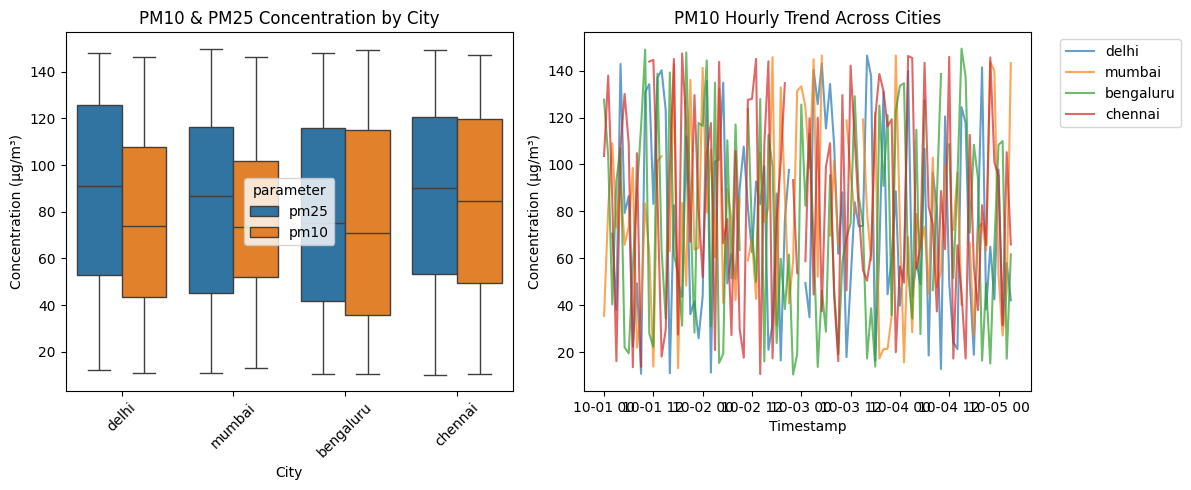

In [2]:
# 5. Visualizing Distributions & Time Series for PM10 and PM25
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df[df['parameter'].isin(['pm10', 'pm25'])], x='city', y='value', hue='parameter')
plt.title("PM10 & PM25 Concentration by City")
plt.xlabel("City")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
for city in df['city'].unique():
    city_pm10 = df[(df['city'] == city) & (df['parameter'] == 'pm10')]
    plt.plot(city_pm10['timestamp'], city_pm10['value'], label=city, alpha=0.7)

plt.title("PM10 Hourly Trend Across Cities")
plt.xlabel("Timestamp")
plt.ylabel("Concentration (µg/m³)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()